# Phase 1, Step 3: Profiling the CFPB complaint sample

**Goal:** find out what the data really looks like before we build the pipeline (Phase 2) and the star schema (Phase 3). This is called **data profiling**.

**Inputs** (made by `src/ingestion/pull_sample.py`):
- `data/raw/monthly_counts.csv`: the exact number of complaints for every month (covers all ~19M complaints, reconciled to the API total).
- `data/raw/sample_monthly.csv`: up to 100 complaints per month, 17,900 rows.

**Caveat:** the sample is *not random*. Each month's 100 rows are the most recently received complaints, so they come from the last day or two of the month. Use it to learn **formats, missing values and category names**. Do **not** use it to claim shares like "X% of complaints are about credit reporting". For those, we'll query the full data later.

Run each cell with **Shift + Enter**, and read the output before moving on.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 60)

sample = pd.read_csv("../data/raw/sample_monthly.csv", dtype=str)
counts = pd.read_csv("../data/raw/monthly_counts.csv")
sample["year"] = sample["sample_month"].str[:4]

print(sample.shape)
sample.head(3)

Matplotlib is building the font cache; this may take a moment.


(17900, 17)


,product,date_sent_to_company,issue,sub_product,zip_code,tags,complaint_id,timely,company_response,submitted_via,company,date_received,state,company_public_response,sub_issue,sample_month,year
0,Mortgage,2012-01-03T05:00:00.000Z,"Loan modification,collection,foreclosure",Conventional fixed mortgage,65685,NaN,9001,Yes,Closed without relief,Web,JPMORGAN CHASE & CO.,2011-12-31T22:41:21.000Z,MO,NaN,NaN,2011-12,2011
1,Mortgage,2012-01-03T05:00:00.000Z,"Application, originator, mortgage broker",Conventional fixed mortgage,94526,NaN,9000,Yes,Closed without relief,Web,"CITIBANK, N.A.",2011-12-31T22:05:35.000Z,CA,NaN,NaN,2011-12,2011
2,Mortgage,2012-01-04T05:00:00.000Z,"Loan servicing, payments, escrow account",Conventional fixed mortgage,08021,NaN,8999,Yes,Closed without relief,Web,"Flagstar Bank, N.A.",2011-12-31T21:58:40.000Z,NJ,NaN,NaN,2011-12,2011


`dtype=str` tells pandas to read **every column as text**. We do that on purpose in profiling: if pandas guessed types, it could silently turn a ZIP like `02134` into the number `2134`. We look first, and cast types later on purpose.

## 1. Volume over time (full population, not the sample)

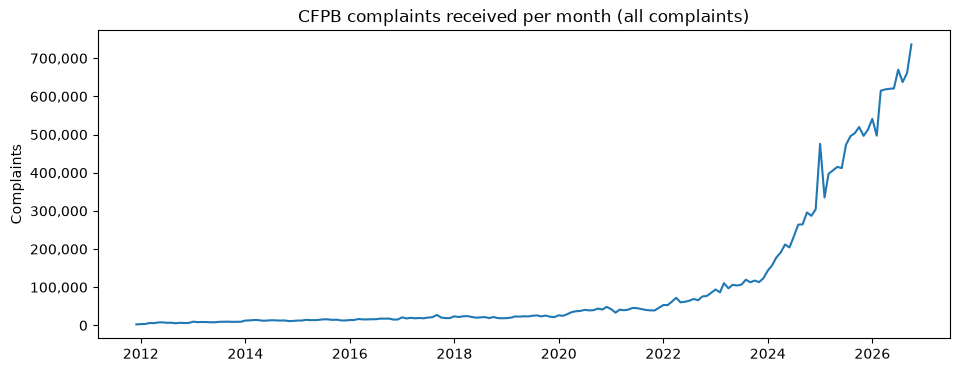

month
2011       2536
2012      72368
2013     108214
2014     152908
2015     168272
2016     191292
2017     242745
2018     257130
2019     277239
2020     444212
2021     495940
2022     800245
2023    1292048
2024    2734268
2025    5442933
2026    6217969
Name: complaints, dtype: int64

In [2]:
counts["month"] = pd.to_datetime(counts["month"])
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(counts["month"], counts["complaints"])
ax.set_title("CFPB complaints received per month (all complaints)")
ax.set_ylabel("Complaints")
ax.yaxis.set_major_formatter(lambda x, pos: f"{x:,.0f}")
plt.show()

yearly = counts.groupby(counts["month"].dt.year)["complaints"].sum()
yearly

## 2. Missing values per column
`isna()` marks each empty cell as True. `.sum()` counts them, `.mean()` gives the share. **Distinct** is how many different values a column has. That's called **cardinality**, and it decides what becomes a dimension table in Phase 3.

In [3]:
profile = pd.DataFrame({
    "missing": sample.isna().sum(),
    "missing_pct": (sample.isna().mean() * 100).round(1),
    "distinct": sample.nunique(),
})
profile.sort_values("missing_pct", ascending=False)

,missing,missing_pct,distinct
tags,15951,89.1,3
company_public_response,10410,58.2,10
sub_issue,5050,28.2,217
sub_product,1947,10.9,75
state,149,0.8,58
product,0,0.0,20
company,0,0.0,1118
sample_month,0,0.0,179
date_received,0,0.0,16217
company_response,0,0.0,8


## 3. Missing values **by year**
A column that is 28% missing overall might be 100% missing in 2012 and 1% in 2026. That would mean the field was *introduced* or *started being filled in* later, not that it's broken. Read this table row by row.

In [4]:
missing_by_year = (sample.drop(columns=["sample_month", "year"]).isna()
                   .groupby(sample["year"]).mean() * 100).round(0).astype(int).T
missing_by_year

year,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
product,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
date_sent_to_company,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
issue,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
sub_product,51,27,27,29,31,36,8,0,0,0,0,0,0,0,0,0
zip_code,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
tags,86,89,87,85,83,83,86,85,90,89,90,90,91,95,98,97
complaint_id,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
timely,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
company_response,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
submitted_via,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


## 4. Keys: is `complaint_id` unique and clean?

In [5]:
print("Rows:", len(sample))
print("Duplicate complaint_ids:", sample["complaint_id"].duplicated().sum())
print("IDs that are not all digits:", (~sample["complaint_id"].str.fullmatch(r"\d+")).sum())

Rows: 17900
Duplicate complaint_ids: 0
IDs that are not all digits: 0


## 5. Dates: how long until the complaint is sent to the company?
`pd.to_datetime(..., utc=True)` turns the text into real timestamps. Subtracting two timestamps gives a duration.

In [6]:
sample["received"] = pd.to_datetime(sample["date_received"], utc=True)
sample["sent"] = pd.to_datetime(sample["date_sent_to_company"], utc=True)
sample["days_to_send"] = (sample["sent"] - sample["received"]).dt.total_seconds() / 86400

print(sample["days_to_send"].describe().round(2))
print()
print("Sent BEFORE received, by year:")
print(sample.loc[sample["days_to_send"] < 0, "year"].value_counts().sort_index())

count    17900.00
mean         2.37
std         13.54
min         -0.96
25%          0.00
50%          0.01
75%          0.34
max        625.42
Name: days_to_send, dtype: float64

Sent BEFORE received, by year:
year
2011     28
2012     77
2013    265
2014    137
Name: count, dtype: int64


Sent *before* received should be impossible. Let's look at the clock times on the sent dates. Hint: 04:00 and 05:00 UTC are midnight in US Eastern time (summer and winter).

In [7]:
sent_time = sample["date_sent_to_company"].str[11:19]
print(sent_time.value_counts().head(5))
print()
print("Share of sent times that are exactly 04:00 or 05:00 UTC, by year:")
print(sent_time.isin(["04:00:00", "05:00:00"]).groupby(sample["year"]).mean().round(2))

date_sent_to_company
04:00:00    1671
05:00:00    1112
23:58:31      13
23:59:09      12
23:57:30      12
Name: count, dtype: int64

Share of sent times that are exactly 04:00 or 05:00 UTC, by year:
year
2011    1.00
2012    1.00
2013    1.00
2014    0.24
2015    0.00
2016    0.00
2017    0.00
2018    0.00
2019    0.00
2020    0.00
2021    0.00
2022    0.00
2023    0.00
2024    0.00
2025    0.00
2026    0.00
Name: date_sent_to_company, dtype: float64


## 6. Categories over time: `product`
`pd.crosstab` counts how often each product appears in each year. Watch for names that **stop** in one year while a similar name **starts** in the same year.

In [8]:
pd.crosstab(sample["product"], sample["year"])

year,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
product,,,,,,,,,,,,,,,,
Bank account or service,0,166,144,115,93,119,36,0,0,0,0,0,0,0,0,0
Checking or savings account,0,0,0,0,0,0,78,135,112,68,52,53,39,23,19,14
Consumer Loan,0,32,31,49,74,65,10,0,0,0,0,0,0,0,0,0
Credit card,51,292,154,115,106,138,36,0,0,0,0,0,28,36,25,13
Credit card or prepaid card,0,0,0,0,0,0,102,126,99,83,99,74,32,0,0,0
Credit reporting,0,34,169,222,254,281,56,0,0,0,0,0,0,0,0,0
Credit reporting or other personal consumer reports,0,0,0,0,0,0,0,0,0,0,0,0,394,1000,1032,888
"Credit reporting, credit repair services, or other personal consumer reports",0,0,0,0,0,0,334,469,619,757,716,886,563,0,0,0
Debt collection,0,0,153,332,294,218,251,234,202,167,184,92,62,94,83,59


## 7. Company response and other small categorical fields

In [9]:
pd.crosstab(sample["company_response"], sample["year"])

year,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
company_response,,,,,,,,,,,,,,,,
Closed,0,37,23,22,18,29,6,0,0,0,0,0,0,0,0,0
Closed with explanation,1,567,890,938,944,945,1011,964,960,1088,1027,792,704,593,732,616
Closed with monetary relief,0,124,110,60,75,65,64,65,45,28,32,22,17,12,9,7
Closed with non-monetary relief,0,120,177,179,159,158,116,167,189,83,140,385,477,594,456,265
Closed with relief,23,80,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Closed without relief,75,268,0,0,0,0,0,0,0,0,0,0,0,0,0,0
In progress,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,110
Untimely response,1,4,0,1,4,3,3,4,6,1,1,1,2,1,3,2


In [10]:
for col in ["timely", "submitted_via", "tags", "company_public_response"]:
    print(sample[col].value_counts(dropna=False), "\n")

timely
Yes    17581
No       319
Name: count, dtype: int64 

submitted_via
Web            15220
Referral        1413
Phone            795
Postal mail      374
Fax               92
Email              6
Name: count, dtype: int64 

tags
NaN                              15951
Servicemember                     1095
Older American                     725
Older American, Servicemember      129
Name: count, dtype: int64 

company_public_response
NaN                                                                                                                        10410
Company has responded to the consumer and the CFPB and chooses not to provide a public response                             6360
Company believes it acted appropriately as authorized by contract or law                                                     564
Company chooses not to provide a public response                                                                             373
Company believes the complaint is the resu

## 8. Geography: `state` and `zip_code`

In [11]:
states_50_dc = set(
    "AL AK AZ AR CA CO CT DE FL GA HI ID IL IN IA KS KY LA ME MD MA MI MN MS MO MT NE NV NH "
    "NJ NM NY NC ND OH OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY DC".split()
)
print("States that are not one of the 50 + DC:")
print(sample.loc[~sample["state"].isin(states_50_dc), "state"].value_counts(dropna=False))

States that are not one of the 50 + DC:
state
NaN                                     149
PR                                       42
AP                                        8
AE                                        6
VI                                        2
AS                                        1
PW                                        1
UNITED STATES MINOR OUTLYING ISLANDS      1
Name: count, dtype: int64


To see ZIP **formats** rather than 6,000 individual ZIPs, we replace every digit with `9`. So `60425` becomes `99999` and `606XX` becomes `999XX`. This is called **pattern profiling**.

In [12]:
zip_pattern = sample["zip_code"].fillna("MISSING").str.replace(r"\d", "9", regex=True)
zip_pattern.value_counts()

zip_code
99999      16489
999XX       1139
XXXXX        269
MISSING        2
999-9          1
Name: count, dtype: int64

## 9. Companies

In [14]:
print("Distinct companies in the sample:", sample["company"].nunique())
sample["company"].value_counts().head(15)

Distinct companies in the sample: 1118


company
EQUIFAX, INC.                             2805
TRANSUNION INTERMEDIATE HOLDINGS, INC.    2622
Experian Information Solutions Inc.       2531
BANK OF AMERICA, NATIONAL ASSOCIATION      907
WELLS FARGO & COMPANY                      733
JPMORGAN CHASE & CO.                       608
CITIBANK, N.A.                             523
CAPITAL ONE FINANCIAL CORPORATION          431
Ocwen Financial Corporation                261
SYNCHRONY FINANCIAL                        247
Navient Solutions, LLC.                    191
NATIONSTAR MORTGAGE LLC                    177
U.S. BANCORP                               165
AMERICAN EXPRESS COMPANY                   158
PNC Bank N.A.                              134
Name: count, dtype: int64